# Importing the important libraries or packages

In [364]:

import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
from pandas.plotting import autocorrelation_plot
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')
from statsmodels.tsa.holtwinters import ExponentialSmoothing,SimpleExpSmoothing
from pmdarima import auto_arima

# Loading and Understanding the data

In [365]:
df=pd.read_csv(r'C:\Users\PATHWAY\Downloads\kingcounty\kingcounty\kc_house_data.csv')
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [366]:
print('data dimension=',df.shape)

data dimension= (21613, 21)


In [367]:
print(df.columns)

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='object')


In [368]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

In [369]:
print(df.dtypes)

id                 int64
date              object
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object


In [370]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,21613.0,4.580302e+09,2.876566e+09,1.000102e+06,2.123049e+09,3.904930e+09,7.308900e+09,9.900000e+09
price,21613.0,5.400881e+05,3.671272e+05,7.500000e+04,3.219500e+05,4.500000e+05,6.450000e+05,7.700000e+06
bedrooms,21613.0,3.370842e+00,9.300618e-01,0.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,21613.0,2.114757e+00,7.701632e-01,0.000000e+00,1.750000e+00,2.250000e+00,2.500000e+00,8.000000e+00
sqft_living,21613.0,2.079900e+03,9.184409e+02,2.900000e+02,1.427000e+03,1.910000e+03,2.550000e+03,1.354000e+04
sqft_lot,21613.0,1.510697e+04,4.142051e+04,5.200000e+02,5.040000e+03,7.618000e+03,1.068800e+04,1.651359e+06
floors,21613.0,1.494309e+00,5.399889e-01,1.000000e+00,1.000000e+00,1.500000e+00,2.000000e+00,3.500000e+00
waterfront,21613.0,7.541757e-03,8.651720e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
view,21613.0,2.343034e-01,7.663176e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
condition,21613.0,3.409430e+00,6.507430e-01,1.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00


#Checking for duplicates

In [371]:
df[df.duplicated(keep=False)]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15


In [372]:
print('Number of duplicates=',df.duplicated().sum())

Number of duplicates= 0


#Checking for missingness

In [373]:
print('missing observations=',df.isna().sum())

missing observations= id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


 Visualizations to help understand the dataset distribution and also identify outliers

Text(0.5, 1.0, 'Price Distribution')

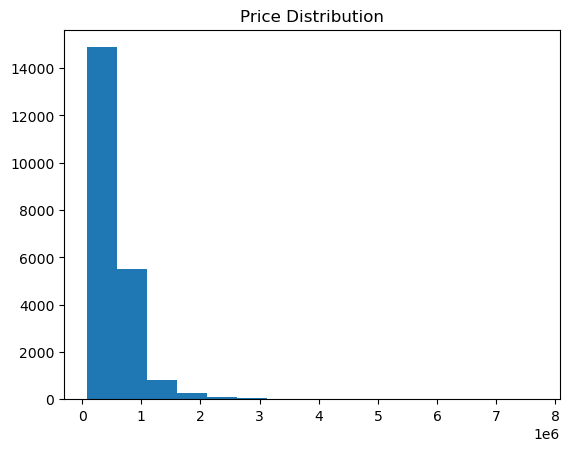

In [374]:
plt.hist(df['price'],bins=15)
plt.title('Price Distribution')

<Axes: xlabel='price', ylabel='Density'>

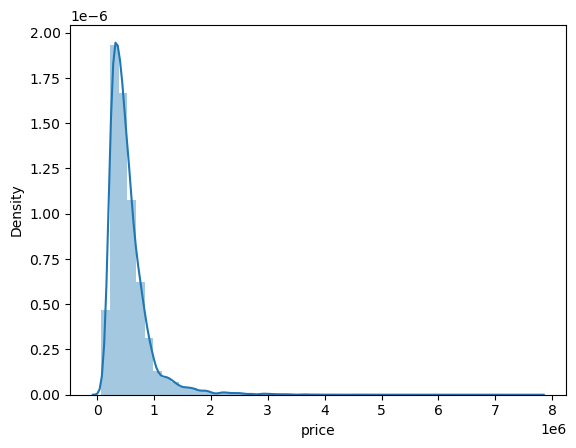

In [375]:
sns.distplot(df['price'])

Text(0.5, 1.0, 'Relationship Between Price and Bedrooms')

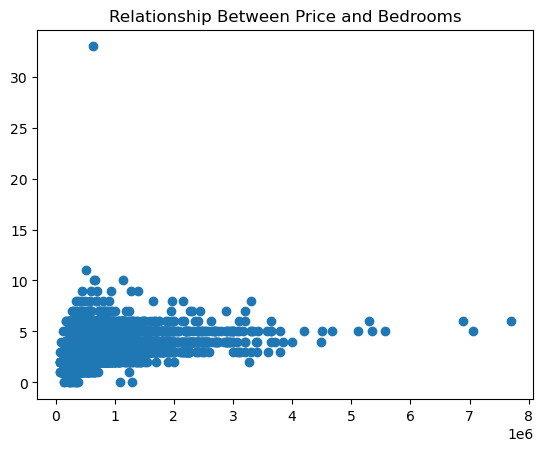

In [376]:
plt.scatter(df['price'],df['bedrooms'])
plt.title('Relationship Between Price and Bedrooms')

Text(0.5, 1.0, 'Relationship Between Price and Bathrooms')

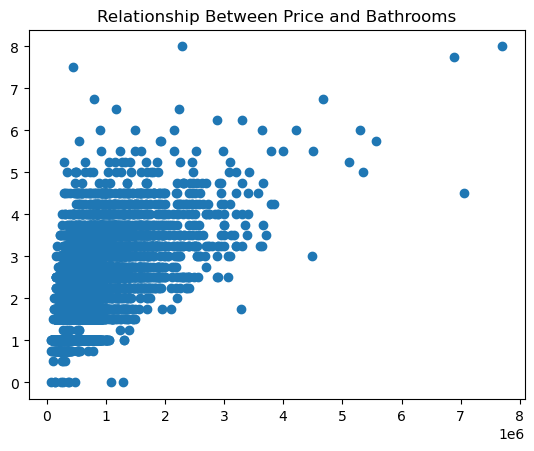

In [377]:
plt.scatter(df['price'],df['bathrooms'])
plt.title('Relationship Between Price and Bathrooms')

([<matplotlib.axis.XTick at 0x1f999490a50>], [Text(1, 0, 'Price')])

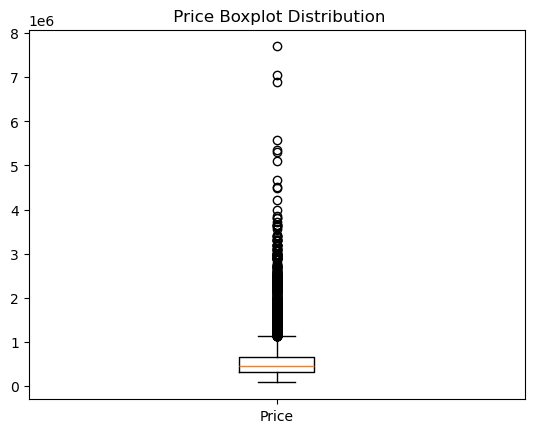

In [378]:
plt.boxplot(df['price'])
plt.title(' Price Boxplot Distribution')
plt.xticks([1],['Price'])

Capping Outliers

In [379]:
#IQR
Q3=df['price'].quantile(.75)
Q1=df['price'].quantile(.25)
IQR= Q3-Q1

upper_limit=Q3+1.5*IQR
lower_limit=Q1-1.5*IQR
df['price']=np.where(df['price']>upper_limit,upper_limit,np.where(df['price']<lower_limit,lower_limit,df['price']))


([<matplotlib.axis.XTick at 0x1f9994ed1d0>], [Text(1, 0, 'Price')])

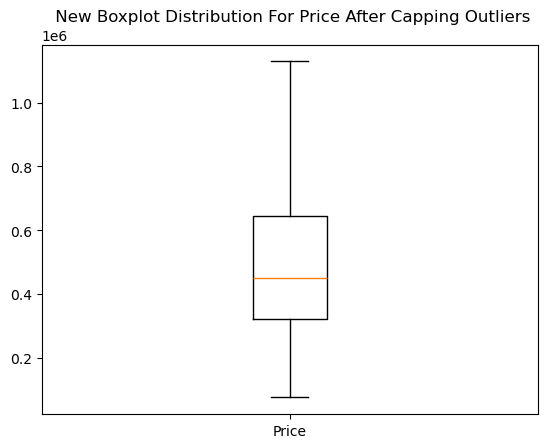

In [380]:
plt.boxplot(df['price'])
plt.title(' New Boxplot Distribution For Price After Capping Outliers')
plt.xticks([1],['Price'])

#Heatmap

<Figure size 1400x1000 with 0 Axes>

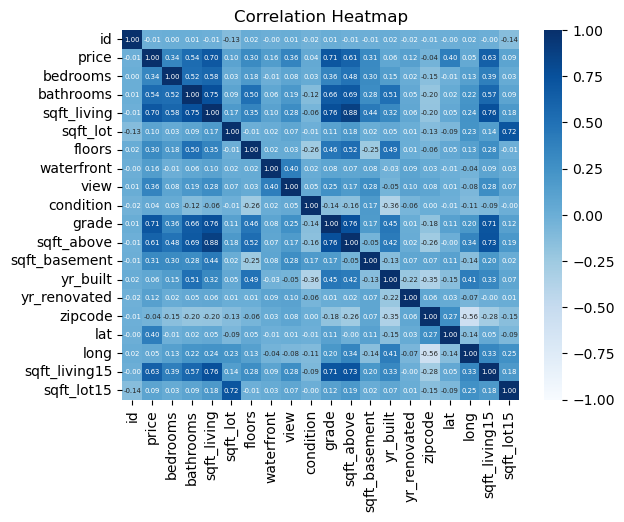

<Figure size 1400x1000 with 0 Axes>

In [381]:
corr=df.corr(numeric_only=True)
sns.heatmap(corr,cmap='Blues',annot=True,vmax=1,vmin=-1,annot_kws={'size':5},fmt='.2f')
plt.title('Correlation Heatmap')
plt.figure(figsize=(14,10))

In [382]:
df['log_price']=np.log(df['price'])


<Figure size 1400x1000 with 0 Axes>

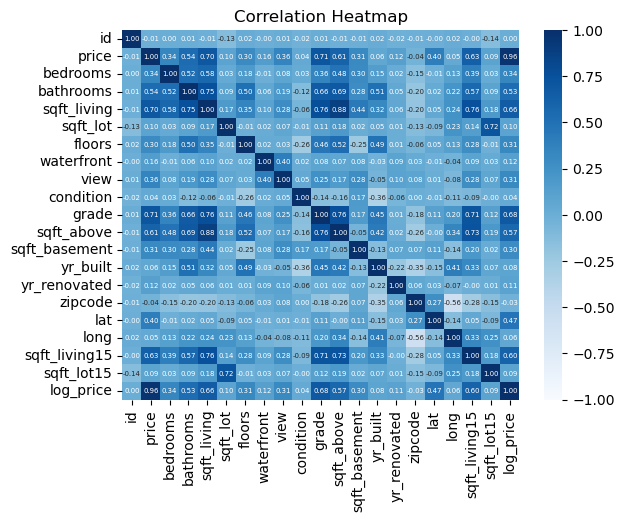

<Figure size 1400x1000 with 0 Axes>

In [383]:
corr=df.corr(numeric_only=True)
sns.heatmap(corr,cmap='Blues',annot=True,vmax=1,vmin=-1,annot_kws={'size':5},fmt='.2f')
plt.title('Correlation Heatmap')
plt.figure(figsize=(14,10))

In [384]:
#Defining the Target Variable
x=df.drop(columns=['price','date','log_price'])
y=df['log_price']

In [385]:
#Splitting the dataset
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=0)

In [386]:
model=Pipeline([('scaler',StandardScaler()),('poly',PolynomialFeatures(degree=2,include_bias=False)),('linear',LinearRegression())])

In [387]:
model.fit(x_train,y_train)

,steps,"[('scaler', ...), ('poly', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,2
,interaction_only,False
,include_bias,False
,order,'C'


In [388]:
y_pred=model.predict(x_test)
y_pred

array([12.80854027, 14.12787456, 13.1189566 , ..., 12.72286499,
       12.50783342, 12.96252108], shape=(4323,))

In [389]:
model.score(x_test,y_test)

0.8158164342373417

In [390]:
MAE=mean_absolute_error(y_test,y_pred)
MAE

0.15549733781438232

In [391]:
MSE=mean_squared_error(y_test,y_pred)
MSE

0.04249210745211161

In [392]:
RMSE=0.5**MSE
RMSE

0.9709762362449108

In [393]:
lasso_pipeline=Pipeline([('scaler',StandardScaler()),('poly',PolynomialFeatures(degree=2,include_bias=False)),('lasso',Lasso(alpha=.05,max_iter=100,tol=0.1))])

In [394]:
lasso_pipeline.fit(x_train,y_train)

,steps,"[('scaler', ...), ('poly', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,2
,interaction_only,False
,include_bias,False
,order,'C'


In [395]:
L1_pred=lasso_pipeline.predict(x_test)
L1_pred

array([12.95847037, 14.02551295, 12.99520725, ..., 12.91309136,
       12.63393444, 12.94516677], shape=(4323,))

In [396]:
lasso_pipeline.score(x_test,y_test)

0.7203691725168713

In [397]:
MAE_lasso=mean_absolute_error(y_test,L1_pred)
MAE_lasso

0.19799256862850242

In [398]:
MSE_lasso=mean_squared_error(y_test,L1_pred)
MSE_lasso

0.06451228761445225

In [399]:
RMSE_lasso=0.5**MSE_lasso
RMSE_lasso

0.9562685357184194

In [400]:
ridge_pipeline=Pipeline([('scaler',StandardScaler()),('poly',PolynomialFeatures(degree=2,include_bias=False)),('Ridege',Ridge(alpha=.05,max_iter=100,tol=0.1))])

In [401]:
ridge_pipeline.fit(x_train,y_train)

,steps,"[('scaler', ...), ('poly', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,2
,interaction_only,False
,include_bias,False
,order,'C'


In [402]:
L2_pred=ridge_pipeline.predict(x_test)
L2_pred

array([12.80855127, 14.12791503, 13.11890039, ..., 12.72293576,
       12.50777378, 12.96257588], shape=(4323,))

In [403]:
ridge_pipeline.score(x_test,y_test)

0.8158108049853081

In [404]:
MAE_ridge=mean_absolute_error(y_test,L2_pred)
MAE_ridge

0.15549996372798394

In [405]:
MSE_ridge=mean_squared_error(y_test,L2_pred)
MSE_ridge

0.042493406149860774

In [406]:
RMSE_ridge=0.5**MSE_ridge
RMSE_ridge

0.9709753621834847

In [407]:
#model pvalues
X=sm.add_constant(x)
pv=sm.OLS(y,X).fit()
pv.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              log_price   R-squared:                       0.736
Model:                            OLS   Adj. R-squared:                  0.735
Method:                 Least Squares   F-statistic:                     3336.
Date:                Tue, 04 Aug 2026   Prob (F-statistic):               0.00
Time:                        02:37:41   Log-Likelihood:                -621.38
No. Observations:               21613   AIC:                             1281.
Df Residuals:                   21594   BIC:                             1432.
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const           -12.0849      3.631     -3.328      0.001     -19.202      -4.968
id             1.598e-12   5.97e-13      2.675      0.007    4.27e-13    2.77e-12
bedrooms          0.0024      0.002      1.045      0.296      -0.002       0.007
bathrooms         0.0603      0.004     14.972      0.000       0.052       0.068
sqft_living     6.32e-05   2.81e-06     22.493      0.000    5.77e-05    6.87e-05
sqft_lot       5.152e-07   5.94e-08      8.672      0.000    3.99e-07    6.32e-07
floors            0.0877      0.004     19.704      0.000       0.079       0.096
waterfront        0.1230      0.021      5.723      0.000       0.081       0.165
view              0.0471      0.003     17.766      0.000       0.042       0.052
condition         0.0625      0.003     21.469      0.000       0.057       0.068
grade             0.1464      0.003     54.920      0.000       0.141       0.152
sqft_above     1.623e-05   2.79e-06      5.816      0.000    1.08e-05    2.17e-05
sqft_basement  4.696e-05   3.28e-06     14.334      0.000    4.05e-05    5.34e-05
yr_built         -0.0029      9e-05    -32.762      0.000      -0.003      -0.003
yr_renovated   3.609e-05   4.53e-06      7.975      0.000    2.72e-05     4.5e-05
zipcode          -0.0005   4.08e-05    -11.828      0.000      -0.001      -0.000
lat               1.3780      0.013    103.685      0.000       1.352       1.404
long             -0.0878      0.016     -5.392      0.000      -0.120      -0.056
sqft_living15     0.0001   4.27e-06     26.211      0.000       0.000       0.000
sqft_lot15    -1.322e-07   9.09e-08     -1.453      0.146    -3.1e-07    4.61e-08
==============================================================================
Omnibus:                      702.457   Durbin-Watson:                   1.979
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1432.533
Skew:                          -0.226   Prob(JB):                    8.50e-312
Kurtosis:                       4.178   Cond. No.                     1.14e+22
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 4.86e-21. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

In [408]:
pv.pvalues

const             8.751531e-04
id                7.481609e-03
bedrooms          2.961647e-01
bathrooms         1.992440e-50
sqft_living      9.130734e-111
sqft_lot          4.534535e-18
floors            1.135047e-85
waterfront        1.060019e-08
view              4.106435e-70
condition        3.438561e-101
grade             0.000000e+00
sqft_above        6.125545e-09
sqft_basement     2.195348e-46
yr_built         8.496596e-230
yr_renovated      1.605187e-15
zipcode           3.511224e-32
lat               0.000000e+00
long              7.031299e-08
sqft_living15    4.271454e-149
sqft_lot15        1.461077e-01
dtype: float64

# Time Series Model

In [409]:
tdf=df[['date','price']]
tdf.head()

,date,price
0,20141013T000000,221900.0
1,20141209T000000,538000.0
2,20150225T000000,180000.0
3,20141209T000000,604000.0
4,20150218T000000,510000.0


In [410]:
tdf.set_index('date')

,price
date,
20141013T000000,221900.0
20141209T000000,538000.0
20150225T000000,180000.0
20141209T000000,604000.0
20150218T000000,510000.0
...,...
20140521T000000,360000.0
20150223T000000,400000.0
20140623T000000,402101.0


In [411]:
tdf['date']=pd.to_datetime(tdf['date'])

In [412]:
tdf.sort_values(by='date',ascending=True,ignore_index=True).head(100)


,date,price
0,2014-05-02,437500.0
1,2014-05-02,790000.0
2,2014-05-02,675000.0
3,2014-05-02,555000.0
4,2014-05-02,440000.0
...,...,...
95,2014-05-05,657100.0
96,2014-05-05,184000.0
97,2014-05-05,549000.0
98,2014-05-05,900000.0


<Axes: >

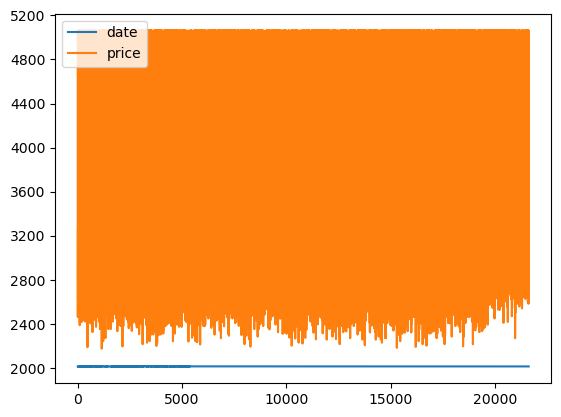

In [413]:
#NO trend and seasonality.Therefore use simple exponential smoothimg and simple moving average
tdf.plot()

# SImple Moving Average

In [414]:
#Using  60 day SMA
tdf['SMA_60']=tdf['price'].rolling(window=60).mean()

<Axes: >

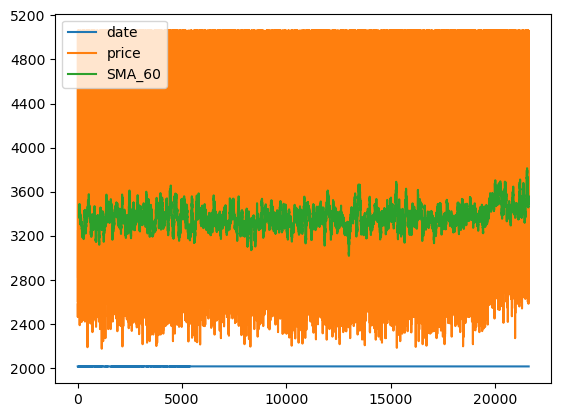

In [415]:
tdf.plot()

In [416]:
#forecasting the next 2 tears where 360 days make a year

In [417]:
last_date=tdf['date'].iloc[-1]
last_SMA=tdf['SMA_60'].iloc[-1]

future_dates=pd.date_range(start=last_date,periods=721)[1:]
forecast=pd.DataFrame({'Forecast':[last_SMA]*720},index=future_dates)

In [418]:
forecast.head()

,Forecast
2014-10-16,558204.283333
2014-10-17,558204.283333
2014-10-18,558204.283333
2014-10-19,558204.283333
2014-10-20,558204.283333


In [419]:
actual=tdf['price'].iloc[59:].values
predi=tdf['SMA_60'].dropna().values

In [420]:
Mae=mean_absolute_error(actual,predi)
Mae

196827.88252528533

In [421]:
Mse=mean_squared_error(actual,predi)
Mse

61242140610.921776

In [422]:
Rmse=0.5**Mse
Rmse

0.0

Text(0.5, 1.0, 'Actual Vrs Predicted Outcome')

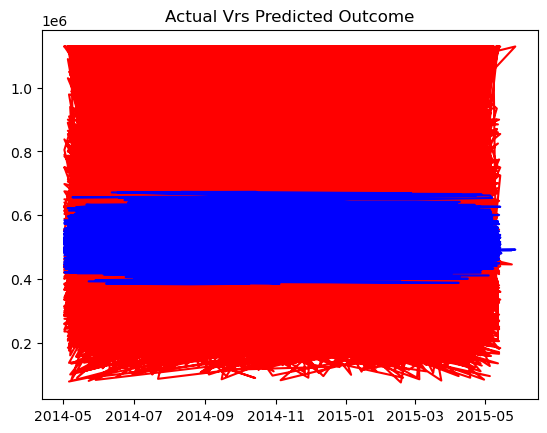

In [423]:
plt.plot(tdf['date'].iloc[59:],actual,label='actual',color='red')
plt.plot(tdf['date'].iloc[59:],predi,label='predicted',color='blue')
plt.title('Actual Vrs Predicted Outcome')

# Simple Exponential Smoothing

In [424]:
SES_model=SimpleExpSmoothing(tdf['price']).fit()

In [425]:
SES_model.summary()

Dep. Variable:,price,No. Observations:,21613
Model:,SimpleExpSmoothing,SSE,1355796173759169.000
Optimized:,True,AIC,537348.891
Trend:,None,BIC,537364.853
Seasonal:,None,AICC,537348.893
Seasonal Periods:,None,Date:,"Tue, 04 Aug 2026"
Box-Cox:,False,Time:,02:37:57
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.0075539,alpha,True
initial_level,2.219e+05,l.0,False
